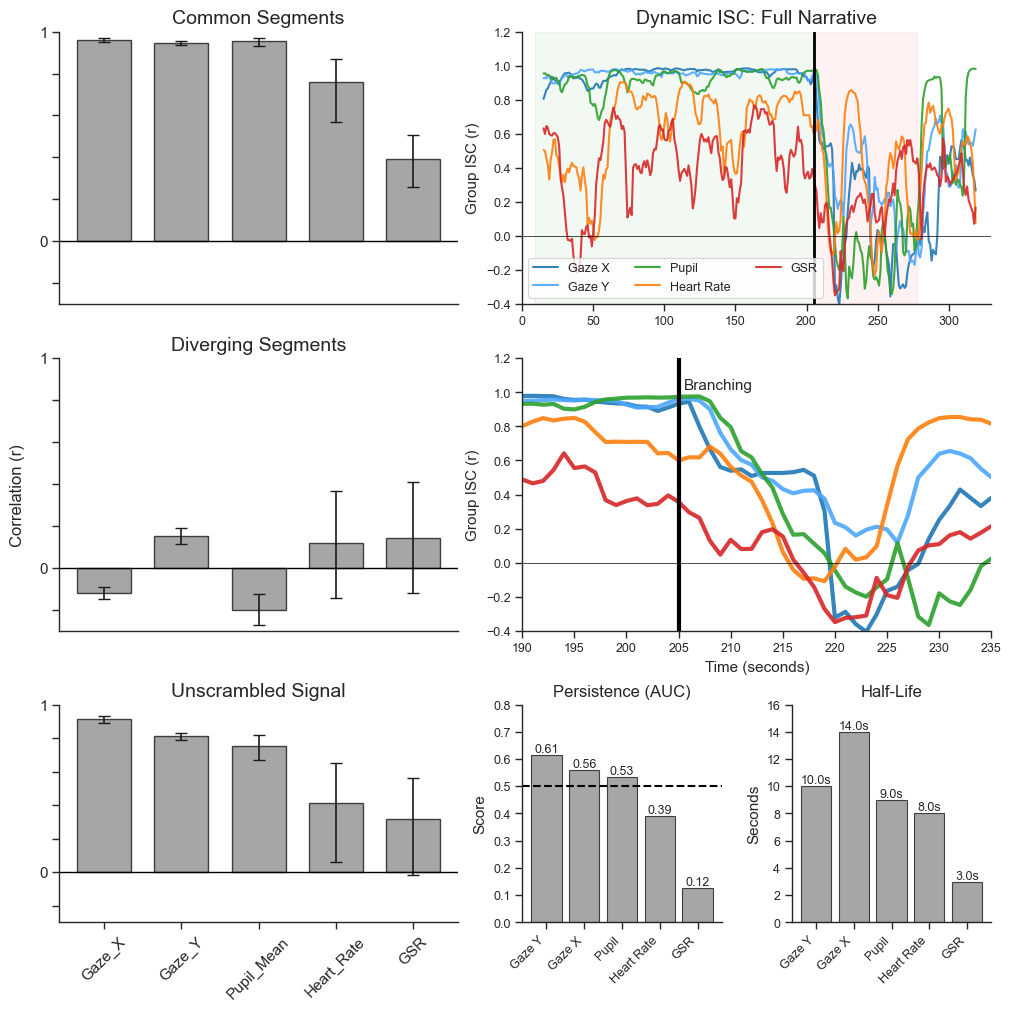

Master Aligned Figure saved to Master_Combined_Panel_Aligned.png


In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import os

# --- GLOBAL SETTINGS ---
sns.set_theme(font='Arial')
sns.set(style="ticks", context="paper")

# --- CONFIGURATION ---
RESULTS_DIR_H2 = "h2_segment_results"
CSV_PATH_SEG   = os.path.join(RESULTS_DIR_H2, "h2_segment_stats.csv")

RESULTS_DIR_H3 = "h3_hysteresis_results"
CSV_PATH_TIME  = os.path.join(RESULTS_DIR_H3, "hysteresis_timecourses.csv")
CSV_PATH_MET   = os.path.join(RESULTS_DIR_H3, "hysteresis_metrics.csv")

OUTPUT_PLOT    = "H2_H3_RQ_Plot_Figure3.png"

# --- DATA LOADING ---
df_seg  = pd.read_csv(CSV_PATH_SEG)
df_hyst = pd.read_csv(CSV_PATH_TIME)
df_met  = pd.read_csv(CSV_PATH_MET)

# --- PRE-PROCESSING ---
# 1. Left Data Sorting
signal_order = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
condition_order = ["Common", "Scrambled", "Unscrambled"]
seg_titles = ["Common Segments", "Diverging Segments", "Unscrambled Signal"]

df_seg['Signal']    = pd.Categorical(df_seg['Signal'], categories=signal_order, ordered=True)
df_seg['Condition'] = pd.Categorical(df_seg['Condition'], categories=condition_order, ordered=True)
df_seg              = df_seg.sort_values(['Condition', 'Signal'])

# 2. Right Data Sorting
hyst_colors = {
    'Gaze_X': '#1f77b4', 'Gaze_Y': '#4da6ff',    
    'Pupil_Mean': '#2ca02c',                     
    'Heart_Rate': '#ff7f0e', 'GSR': '#d62728'    
}
hyst_labels = {
    'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y',
    'Pupil_Mean': 'Pupil', 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'
}
BRANCH_TIME = 205
df_met = df_met.sort_values('Persistence_Score', ascending=False)


# ==========================================
# MASTER PLOTTING (FLATTENED GRID STRATEGY)
# ==========================================

fig = plt.figure(figsize=(10, 10), constrained_layout=True)

# Define a single 3x3 Grid.
# width_ratios: [Left_Col, Right_Sub_1, Right_Sub_2]
# We give the Left column '1.4' weight, and the two Right sub-columns '1' weight each.
# This makes the Left Panel take roughly 40% width and Right Panel 60% total.
gs = gridspec.GridSpec(3, 3, figure=fig, 
                       width_ratios=[2, 1, 1], 
                       height_ratios=[1, 1, 0.8])

# ==========================================
# LEFT PANEL (Column 0)
# ==========================================
axes_left = []

for i, cond in enumerate(condition_order):
    # Plot in Column 0, Row i
    ax = fig.add_subplot(gs[i, 0])
    axes_left.append(ax)
    
    subset = df_seg[df_seg['Condition'] == cond]
    x_pos = np.arange(len(signal_order))
    
    # Bar Plot
    ax.bar(x_pos, subset['Mean_r'],
           yerr=[subset['Err_Low'], subset['Err_High']],
           capsize=4, color='gray', edgecolor='black', 
           width=0.7, alpha=0.7, linewidth=1.0)
    
    ax.set_title(seg_titles[i], loc='center', fontsize=14)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_ylim(-0.3, 1.0)
    
    # Custom Y-Ticks
    ticks = [-0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    ax.set_yticks(ticks)
    tick_labels = ["", "0", "", "", "", "", "1"]
    ax.set_yticklabels(tick_labels, fontsize=11)
    
    # Remove X-ticks for top two rows
    if i < 2:
        ax.set_xticks([])
    else:
        # X-labels only on bottom row
        ax.set_xticks(x_pos)
        ax.set_xticklabels(signal_order, fontsize=10, rotation=45)

# Y-label only on middle plot to save space
axes_left[1].set_ylabel("Correlation (r)", fontsize=12, labelpad=10)


# ==========================================
# RIGHT PANEL (Columns 1 & 2)
# ==========================================

# 1. Macro View (Top Row)
# Span columns 1 and 2 (gs[0, 1:])
ax_macro = fig.add_subplot(gs[0, 1:]) 

for sig in signal_order:
    sub = df_hyst[df_hyst['Signal'] == sig]
    ax_macro.plot(sub['Time_Sec'], sub['Mean_r'], color=hyst_colors[sig], 
                  label=hyst_labels[sig], lw=1.5, alpha=0.9)

ax_macro.axvline(BRANCH_TIME, color='black', lw=2)
ax_macro.axvspan(9, BRANCH_TIME, color='green', alpha=0.05)
ax_macro.axvspan(BRANCH_TIME, 278, color='red', alpha=0.05)
ax_macro.set_title("Dynamic ISC: Full Narrative", loc='center', fontsize=14)
ax_macro.set_ylim(-0.4, 1.2)
ax_macro.set_xlim(0, 330)
ax_macro.axhline(0, color='black', lw=0.5)
ax_macro.set_ylabel("Group ISC (r)", fontsize=11)
ax_macro.legend(loc='lower left', ncol=3, fontsize=9, frameon=True)


# 2. Micro View (Middle Row)
# Span columns 1 and 2 (gs[1, 1:])
ax_micro = fig.add_subplot(gs[1, 1:])

x_start, x_end = 190, 235
for sig in signal_order:
    sub = df_hyst[df_hyst['Signal'] == sig]
    sub = sub[(sub['Time_Sec'] >= x_start) & (sub['Time_Sec'] <= x_end)]
    ax_micro.plot(sub['Time_Sec'], sub['Mean_r'], color=hyst_colors[sig], lw=3, alpha=0.9)

ax_micro.axvline(BRANCH_TIME, color='black', lw=3)
ax_micro.text(BRANCH_TIME+0.5, 1.02, "Branching", fontsize=11)
#ax_micro.set_title("Decay After Narrative Branching", loc='center', fontsize=14)
#ax_micro.text(192, -0.2, "Decay After Narrative Branching",  fontsize=14)
ax_micro.set_ylim(-0.4, 1.2)
ax_micro.set_xlim(x_start, x_end)
ax_micro.axhline(0, color='black', lw=0.5)
ax_micro.set_ylabel("Group ISC (r)", fontsize=11)
ax_micro.set_xlabel("Time (seconds)", fontsize=11)


# 3. Metrics (Bottom Row) - Split into separate cells
# Persistence: Row 2, Col 1
ax_pers = fig.add_subplot(gs[2, 1]) 
# Half-Life:   Row 2, Col 2
ax_half = fig.add_subplot(gs[2, 2])

x_idx_met = range(len(df_met))

# Persistence Bar Chart
bars1 = ax_pers.bar(x_idx_met, df_met['Persistence_Score'], color='gray', edgecolor='black', alpha=0.7)
ax_pers.axhline(0.5, color='black', linestyle='--', lw=1.5, label='Window Artifact')
ax_pers.set_title("Persistence (AUC)", loc='center', fontsize=12)
ax_pers.set_ylabel("Score", fontsize=11)
ax_pers.set_ylim(0, 0.8)
ax_pers.set_xticks(x_idx_met)
ax_pers.set_xticklabels(df_met['Signal'].map(hyst_labels), rotation=45, ha='right', fontsize=10)

for bar in bars1:
    ax_pers.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01, 
                 f"{bar.get_height():.2f}", ha='center', fontsize=9)

# Half-Life Bar Chart
bars2 = ax_half.bar(x_idx_met, df_met['Half_Life'], color='gray', edgecolor='black', alpha=0.7)
ax_half.set_title("Half-Life", loc='center', fontsize=12)
ax_half.set_ylabel("Seconds", fontsize=11)
ax_half.set_ylim(0, 16)
ax_half.set_xticks(x_idx_met)
ax_half.set_xticklabels(df_met['Signal'].map(hyst_labels), rotation=45, ha='right', fontsize=10)

for bar in bars2:
    ax_half.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.2, 
                 f"{bar.get_height():.1f}s", ha='center', fontsize=9)


# ==========================================
# FINAL CLEANUP
# ==========================================

# Apply global tick size fix
for ax in fig.axes:
    ax.tick_params(axis='both', which='major', labelsize=9) 
    sns.despine(ax=ax)

# Re-assert specific labels for the left column (loop sometimes resets them)
axes_left[0].set_yticklabels(tick_labels, fontsize=11)
axes_left[1].set_yticklabels(tick_labels, fontsize=11)
axes_left[2].set_yticklabels(tick_labels, fontsize=11)
axes_left[2].set_xticklabels(signal_order, fontsize=11)

plt.savefig(OUTPUT_PLOT, dpi=300)
plt.show()

print(f"Master Aligned Figure saved to {OUTPUT_PLOT}")